# Machine Learning Application & Model Evaluation
## Customer Churn Prediction (Telco) — comparing multiple classifiers

**Problem:** Predict whether a telecom customer will churn (binary classification).
**Why it matters:** Retaining a customer is cheaper than acquiring a new one, so a model that flags likely churners lets a company target retention offers.

**Plan**
1. Load and clean the data
2. Exploratory data analysis (EDA)
3. Preprocessing inside a `Pipeline` (no data leakage)
4. Train 6 algorithms and validate with stratified 5-fold cross-validation
5. Diagnose overfitting / underfitting (train vs CV gap, validation curve, learning curve)
6. Tune the best models (`GridSearchCV`)
7. Final evaluation on the untouched test set
8. Select and justify the final model

## 1. Imports and setup

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_validate,
                                     GridSearchCV, validation_curve, learning_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay, classification_report)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

## 2. Load the data
Dataset: IBM **Telco Customer Churn** (7,043 customers, 21 columns).
Put `WA_Fn-UseC_-Telco-Customer-Churn.csv` (from Kaggle: *blastchar/telco-customer-churn*) next to this notebook. If the file is not found, the cell downloads the same IBM sample data from GitHub.

In [4]:
import os

LOCAL = "WA_Fn-UseC_-Telco-Customer-Churn.csv"
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(LOCAL if os.path.exists(LOCAL) else URL)
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 3. Data cleaning
- `TotalCharges` is stored as text; 11 rows hold a blank space. These are brand-new customers (`tenure = 0`), so their total charges are genuinely 0.
- `customerID` is only an identifier and carries no predictive signal, so it is dropped.
- The target `Churn` is mapped to 1 (Yes) / 0 (No).

In [6]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print("Their tenure values:", df.loc[df["TotalCharges"].isna(), "tenure"].unique())

df["TotalCharges"] = df["TotalCharges"].fillna(0)
df = df.drop(columns="customerID")
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

print("Duplicate rows:", df.duplicated().sum())
print("Remaining missing values:", df.isna().sum().sum())

Missing TotalCharges: 11
Their tenure values: [0]
Duplicate rows: 22
Remaining missing values: 0


## 4. Exploratory data analysis

Churn rate: 26.5%  (class ratio ~ 73%:27%)


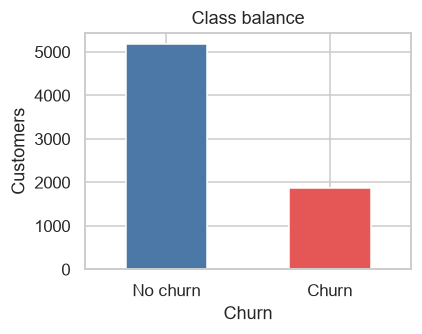

In [7]:
churn_rate = df["Churn"].mean()
print(f"Churn rate: {churn_rate:.1%}  (class ratio ~ {1-churn_rate:.0%}:{churn_rate:.0%})")

fig, ax = plt.subplots(figsize=(4, 3.2))
df["Churn"].value_counts().rename({0: "No churn", 1: "Churn"}).plot(kind="bar", ax=ax, color=["#4C78A8", "#E45756"])
ax.set_title("Class balance"); ax.set_ylabel("Customers"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

**Observation:** the classes are imbalanced (roughly 73:27). Accuracy alone would be misleading — a model that always predicts "No churn" already gets ~73%. We therefore focus on **recall, F1, ROC-AUC and PR-AUC** for the churn class.

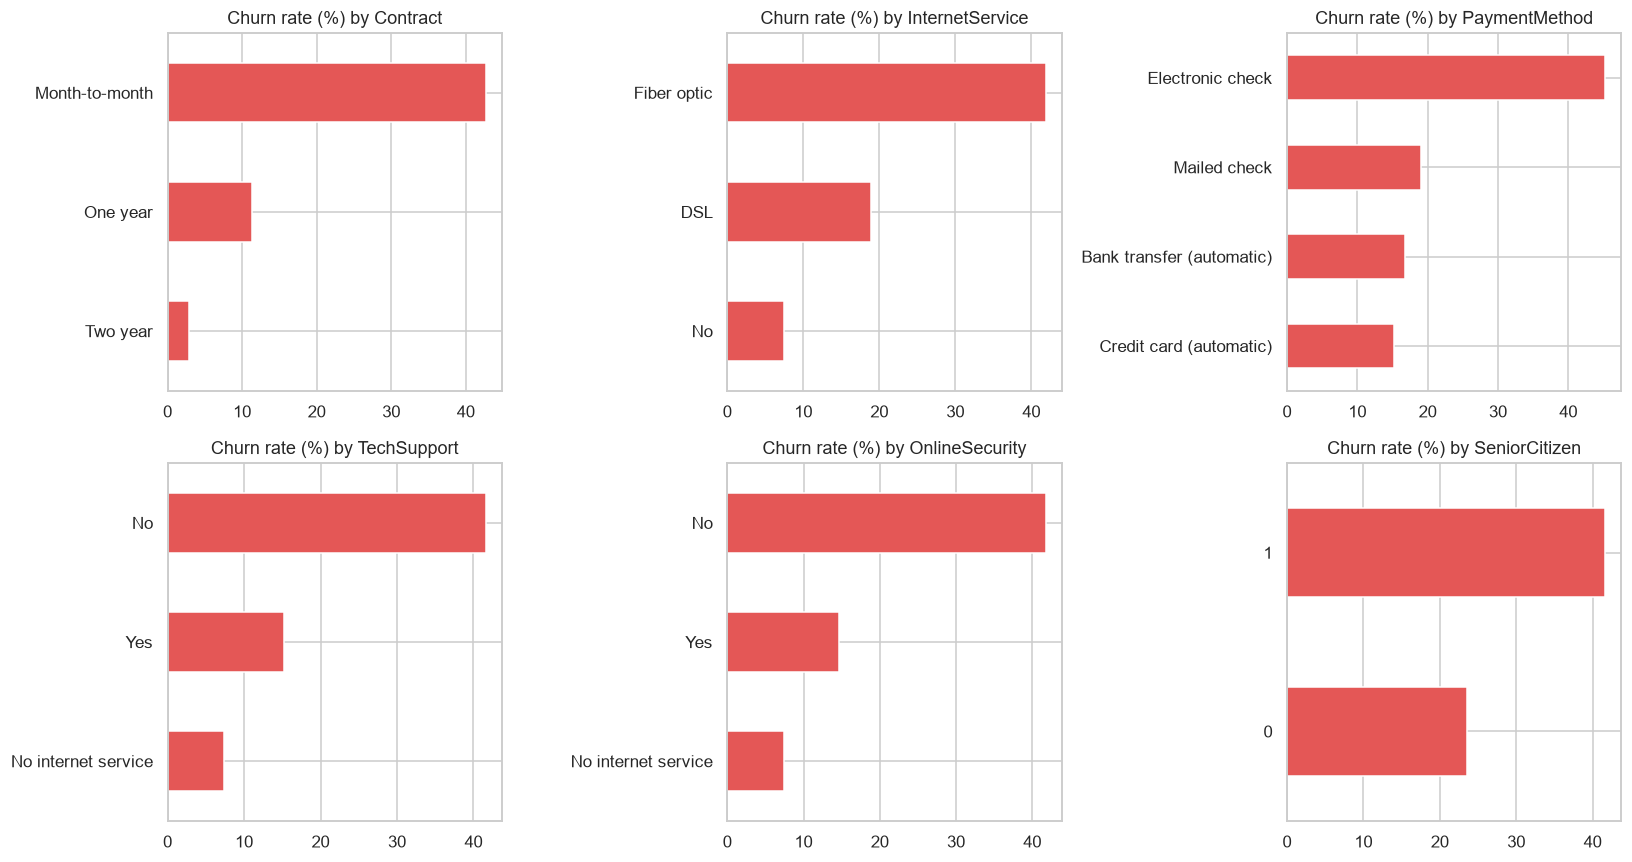

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity", "SeniorCitizen"]):
    (df.groupby(col)["Churn"].mean() * 100).sort_values().plot(kind="barh", ax=ax, color="#E45756")
    ax.set_title(f"Churn rate (%) by {col}"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

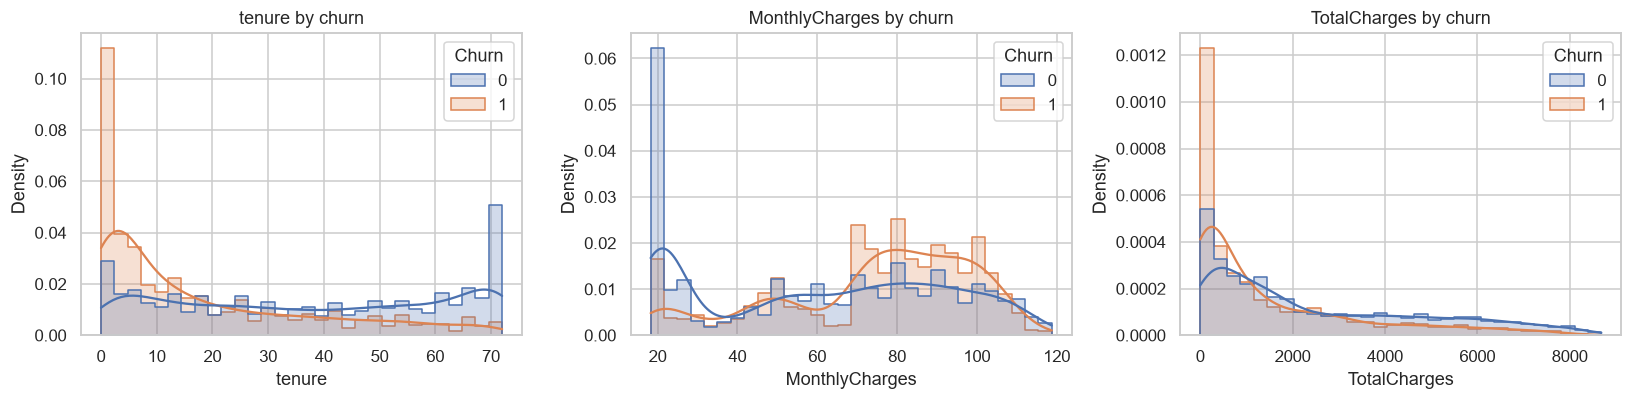

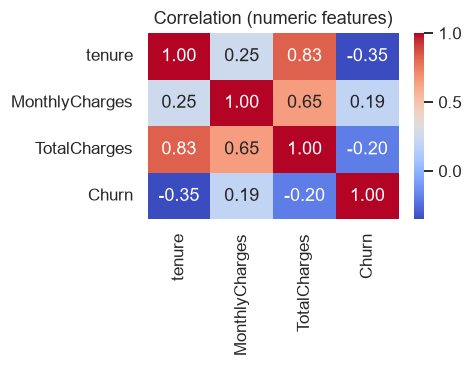

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=df, x=col, hue="Churn", bins=30, kde=True, ax=ax, element="step", stat="density", common_norm=False)
    ax.set_title(f"{col} by churn")
plt.tight_layout(); plt.show()

plt.figure(figsize=(4.5, 3.5))
sns.heatmap(df[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation (numeric features)"); plt.tight_layout(); plt.show()

**Key findings**
- Month-to-month contracts, fiber-optic internet and electronic-check payers churn the most.
- Customers with tech support / online security and long-term contracts churn far less.
- Churners tend to have short tenure and higher monthly charges.
- `TotalCharges` is strongly correlated with `tenure` (it is roughly tenure × monthly charge), so some multicollinearity exists — fine for tree models, and regularisation handles it for logistic regression.

## 5. Train/test split and preprocessing pipeline
- **Stratified 80/20 split** keeps the churn ratio equal in both sets. The test set is not touched until the final evaluation.
- Preprocessing sits inside a `Pipeline`, so scalers/encoders are fitted only on the training folds during cross-validation (**no data leakage**).

In [10]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, f"churn={y_train.mean():.3f}")
print("Test :", X_test.shape,  f"churn={y_test.mean():.3f}")

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in X.columns if c not in num_cols]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_cols),
])

Train: (5634, 19) churn=0.265
Test : (1409, 19) churn=0.265


## 6. Candidate models
Six algorithms from different families. `class_weight="balanced"` is used where supported to address the imbalance; Gradient Boosting and KNN do not support it, so they are judged by the threshold-free metrics (ROC-AUC / PR-AUC) as well.

| Model | Family | Why included |
|---|---|---|
| Logistic Regression | Linear | Interpretable baseline |
| KNN | Instance-based | Simple non-parametric contrast |
| SVM (RBF) | Kernel | Non-linear boundary |
| Decision Tree (unrestricted) | Tree | Expected to overfit — a useful demonstration |
| Random Forest | Bagging ensemble | Reduces tree variance |
| Gradient Boosting | Boosting ensemble | Usually strongest on tabular data |

In [11]:
def make(model):
    return Pipeline([("prep", preprocess), ("clf", model)])

models = {
    "Logistic Regression": make(LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    "KNN":                 make(KNeighborsClassifier(n_neighbors=15)),
    "SVM (RBF)":           make(SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE)),
    "Decision Tree":       make(DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    "Random Forest":       make(RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)),
    "Gradient Boosting":   make(GradientBoostingClassifier(random_state=RANDOM_STATE)),
}

## 7. Validation: stratified 5-fold cross-validation
Every model is evaluated on the **training set only** with 5 stratified folds. We record both train and validation scores, so the train–validation gap exposes overfitting.

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc", "average_precision"]

rows, raw = [], {}
for name, pipe in models.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring,
                         return_train_score=True, n_jobs=-1)
    raw[name] = res
    rows.append({
        "Model": name,
        "Accuracy": res["test_accuracy"].mean(),
        "Precision": res["test_precision"].mean(),
        "Recall": res["test_recall"].mean(),
        "F1": res["test_f1"].mean(),
        "ROC-AUC": res["test_roc_auc"].mean(),
        "ROC-AUC std": res["test_roc_auc"].std(),
        "PR-AUC": res["test_average_precision"].mean(),
        "Train ROC-AUC": res["train_roc_auc"].mean(),
        "Train F1": res["train_f1"].mean(),
    })

cv_results = pd.DataFrame(rows).set_index("Model")
cv_results["AUC gap (train-CV)"] = cv_results["Train ROC-AUC"] - cv_results["ROC-AUC"]
cv_results["F1 gap (train-CV)"] = cv_results["Train F1"] - cv_results["F1"]
cv_results.sort_values("ROC-AUC", ascending=False).round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,ROC-AUC std,PR-AUC,Train ROC-AUC,Train F1,AUC gap (train-CV),F1 gap (train-CV)
Model,,,,,,,,,,,
Gradient Boosting,0.803,0.662,0.529,0.588,0.848,0.013,0.668,0.888,0.647,0.040,0.059
Logistic Regression,0.749,0.518,0.803,0.629,0.846,0.012,0.660,0.850,0.634,0.004,0.004
SVM (RBF),0.752,0.521,0.783,0.626,0.826,0.011,0.602,0.876,0.658,0.050,0.033
Random Forest,0.777,0.569,0.654,0.609,0.824,0.011,0.612,1.000,0.991,0.176,0.382
KNN,0.787,0.605,0.566,0.585,0.824,0.008,0.592,0.868,0.631,0.044,0.047
Decision Tree,0.738,0.508,0.495,0.501,0.661,0.014,0.386,1.000,0.996,0.339,0.495


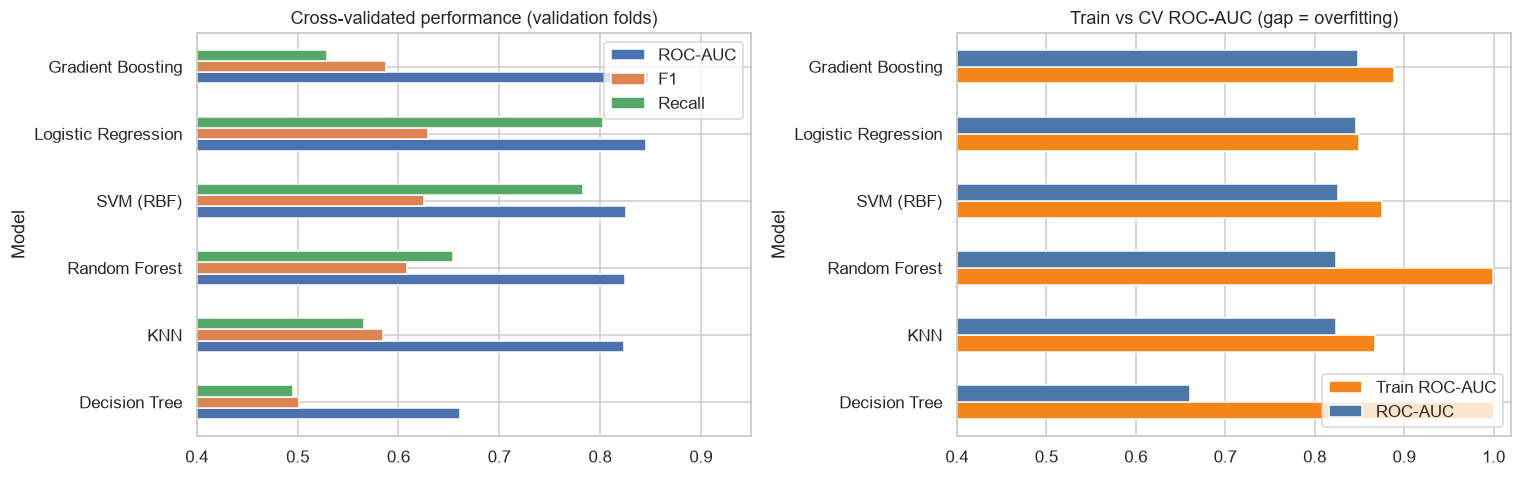

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cv_results[["ROC-AUC", "F1", "Recall"]].sort_values("ROC-AUC").plot(kind="barh", ax=axes[0])
axes[0].set_title("Cross-validated performance (validation folds)"); axes[0].set_xlim(0.4, 0.95)

cv_results[["Train ROC-AUC", "ROC-AUC"]].sort_values("ROC-AUC").plot(kind="barh", ax=axes[1], color=["#F58518", "#4C78A8"])
axes[1].set_title("Train vs CV ROC-AUC (gap = overfitting)"); axes[1].set_xlim(0.4, 1.02)
plt.tight_layout(); plt.show()

## 8. Overfitting and underfitting diagnosis

In [14]:
def diagnose(row):
    gap, cv_auc = row["AUC gap (train-CV)"], row["ROC-AUC"]
    if gap > 0.10:
        return "Overfitting (large train-CV gap)"
    if cv_auc < 0.78 and gap < 0.05:
        return "Underfitting / limited capacity (low on both)"
    return "Good fit (small gap)"

diag = cv_results[["Train ROC-AUC", "ROC-AUC", "AUC gap (train-CV)"]].copy()
diag["Diagnosis"] = cv_results.apply(diagnose, axis=1)
diag.round(3)

,Train ROC-AUC,ROC-AUC,AUC gap (train-CV),Diagnosis
Model,,,,
Logistic Regression,0.850,0.846,0.004,Good fit (small gap)
KNN,0.868,0.824,0.044,Good fit (small gap)
SVM (RBF),0.876,0.826,0.050,Good fit (small gap)
Decision Tree,1.000,0.661,0.339,Overfitting (large train-CV gap)
Random Forest,1.000,0.824,0.176,Overfitting (large train-CV gap)
Gradient Boosting,0.888,0.848,0.040,Good fit (small gap)


### 8a. Validation curve — Decision Tree depth (bias–variance trade-off)
Shallow trees underfit (high bias); fully grown trees memorise the training data (high variance).

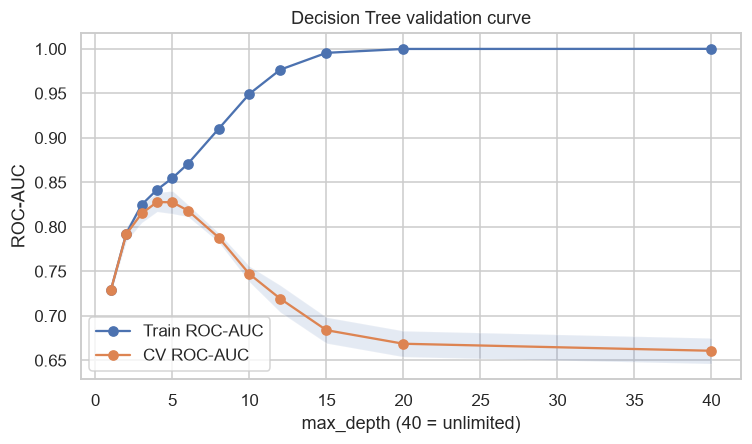

Best depth by CV ROC-AUC: 4


In [15]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, None]
depth_vals = [d if d is not None else 40 for d in depths]

tree_pipe = make(DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))
train_sc, val_sc = validation_curve(tree_pipe, X_train, y_train,
                                    param_name="clf__max_depth", param_range=depths,
                                    cv=cv, scoring="roc_auc", n_jobs=-1)

plt.figure(figsize=(7, 4.2))
plt.plot(depth_vals, train_sc.mean(1), "o-", label="Train ROC-AUC")
plt.plot(depth_vals, val_sc.mean(1), "o-", label="CV ROC-AUC")
plt.fill_between(depth_vals, val_sc.mean(1) - val_sc.std(1), val_sc.mean(1) + val_sc.std(1), alpha=0.15)
plt.xlabel("max_depth (40 = unlimited)"); plt.ylabel("ROC-AUC")
plt.title("Decision Tree validation curve"); plt.legend(); plt.tight_layout(); plt.show()

best_depth = depth_vals[int(val_sc.mean(1).argmax())]
print("Best depth by CV ROC-AUC:", best_depth)

### 8b. Learning curves — does more data help? (Decision Tree vs Random Forest vs Logistic Regression)

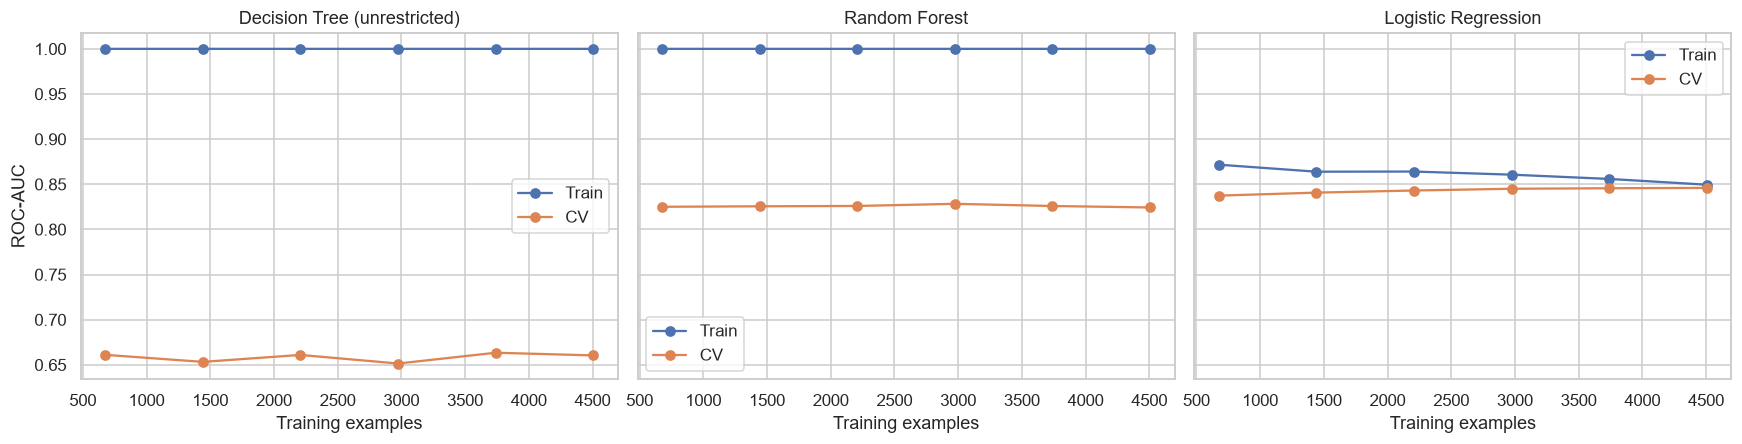

In [16]:
lc_models = {
    "Decision Tree (unrestricted)": models["Decision Tree"],
    "Random Forest": models["Random Forest"],
    "Logistic Regression": models["Logistic Regression"],
}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, (name, pipe) in zip(axes, lc_models.items()):
    sizes, tr, va = learning_curve(pipe, X_train, y_train, cv=cv, scoring="roc_auc",
                                   train_sizes=np.linspace(0.15, 1.0, 6), n_jobs=-1, random_state=RANDOM_STATE)
    ax.plot(sizes, tr.mean(1), "o-", label="Train")
    ax.plot(sizes, va.mean(1), "o-", label="CV")
    ax.set_title(name); ax.set_xlabel("Training examples"); ax.legend()
axes[0].set_ylabel("ROC-AUC")
plt.tight_layout(); plt.show()

**Reading the curves**
- *Decision Tree:* train score stays near 1.0 while CV is far lower → **high variance / overfitting**.
- *Random Forest:* also reaches a very high train score, but its CV score is much better than the single tree, showing how bagging reduces variance (a gap remains).
- *Logistic Regression:* train and CV curves are close together and plateau → low variance; further gains need more expressive features/models (**mild bias / capacity limit**), not more data.

## 9. Hyper-parameter tuning
The three most promising models are tuned with `GridSearchCV` (5-fold, optimising ROC-AUC) on the training set. Regularisation parameters (`C`, `max_depth`, `min_samples_leaf`, `learning_rate`) directly control the overfitting/underfitting trade-off.

In [17]:
grids = {
    "Logistic Regression": (models["Logistic Regression"],
        {"clf__C": [0.01, 0.05, 0.1, 0.5, 1, 5]}),
    "Random Forest": (models["Random Forest"],
        {"clf__max_depth": [4, 6, 8, 12], "clf__min_samples_leaf": [5, 10, 20], "clf__n_estimators": [300]}),
    "Gradient Boosting": (models["Gradient Boosting"],
        {"clf__n_estimators": [100, 200], "clf__learning_rate": [0.03, 0.05, 0.1],
         "clf__max_depth": [2, 3], "clf__subsample": [0.8]}),
}

tuned, tune_rows = {}, []
for name, (pipe, grid) in grids.items():
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1, return_train_score=True)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    i = gs.best_index_
    tune_rows.append({"Model": name,
                      "Best CV ROC-AUC": gs.best_score_,
                      "Train ROC-AUC": gs.cv_results_["mean_train_score"][i],
                      "Gap": gs.cv_results_["mean_train_score"][i] - gs.best_score_,
                      "Best params": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}})
tuning = pd.DataFrame(tune_rows).set_index("Model")
pd.set_option("display.max_colwidth", 120)
tuning.round(4)

,Best CV ROC-AUC,Train ROC-AUC,Gap,Best params
Model,,,,
Logistic Regression,0.8462,0.8498,0.0036,{'C': 5}
Random Forest,0.8481,0.8791,0.0310,"{'max_depth': 12, 'min_samples_leaf': 20, 'n_estimators': 300}"
Gradient Boosting,0.8506,0.8769,0.0262,"{'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}"


In [18]:
# Also include a depth-limited Decision Tree to show the fix for overfitting
gs_tree = GridSearchCV(models["Decision Tree"],
                       {"clf__max_depth": [3, 4, 5, 6, 8], "clf__min_samples_leaf": [10, 20, 50]},
                       cv=cv, scoring="roc_auc", n_jobs=-1, return_train_score=True).fit(X_train, y_train)
tuned["Decision Tree (pruned)"] = gs_tree.best_estimator_
i = gs_tree.best_index_
print("Pruned tree best params:", gs_tree.best_params_)
print(f"Train ROC-AUC {gs_tree.cv_results_['mean_train_score'][i]:.3f} | CV ROC-AUC {gs_tree.best_score_:.3f} "
      f"| gap {gs_tree.cv_results_['mean_train_score'][i] - gs_tree.best_score_:.3f}  (unrestricted tree gap was "
      f"{cv_results.loc['Decision Tree','AUC gap (train-CV)']:.3f})")

Pruned tree best params: {'clf__max_depth': 6, 'clf__min_samples_leaf': 50}
Train ROC-AUC 0.862 | CV ROC-AUC 0.831 | gap 0.030  (unrestricted tree gap was 0.339)


## 10. Final evaluation on the held-out test set
Each tuned model (plus the untuned SVM and KNN for completeness) is fitted on the full training set and scored **once** on the test set.

In [19]:
final_models = dict(tuned)
for n in ["SVM (RBF)", "KNN"]:
    final_models[n] = models[n]

def scores_of(model, X_):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_)[:, 1]
    return model.decision_function(X_)

rows = []
for name, m in final_models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    s = scores_of(m, X_test)
    rows.append({"Model": name,
                 "Accuracy": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, s),
                 "PR-AUC": average_precision_score(y_test, s)})
test_results = pd.DataFrame(rows).set_index("Model").sort_values("ROC-AUC", ascending=False)
test_results.round(3)

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
Model,,,,,,
Gradient Boosting,0.804,0.670,0.516,0.583,0.846,0.662
Random Forest,0.753,0.523,0.791,0.630,0.845,0.652
Logistic Regression,0.740,0.506,0.783,0.615,0.841,0.628
Decision Tree (pruned),0.752,0.521,0.789,0.628,0.836,0.628
SVM (RBF),0.746,0.514,0.775,0.618,0.822,0.594
KNN,0.779,0.587,0.567,0.577,0.818,0.590


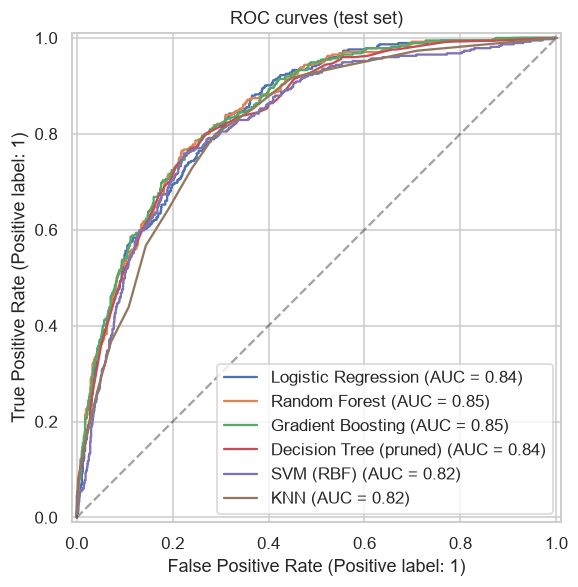

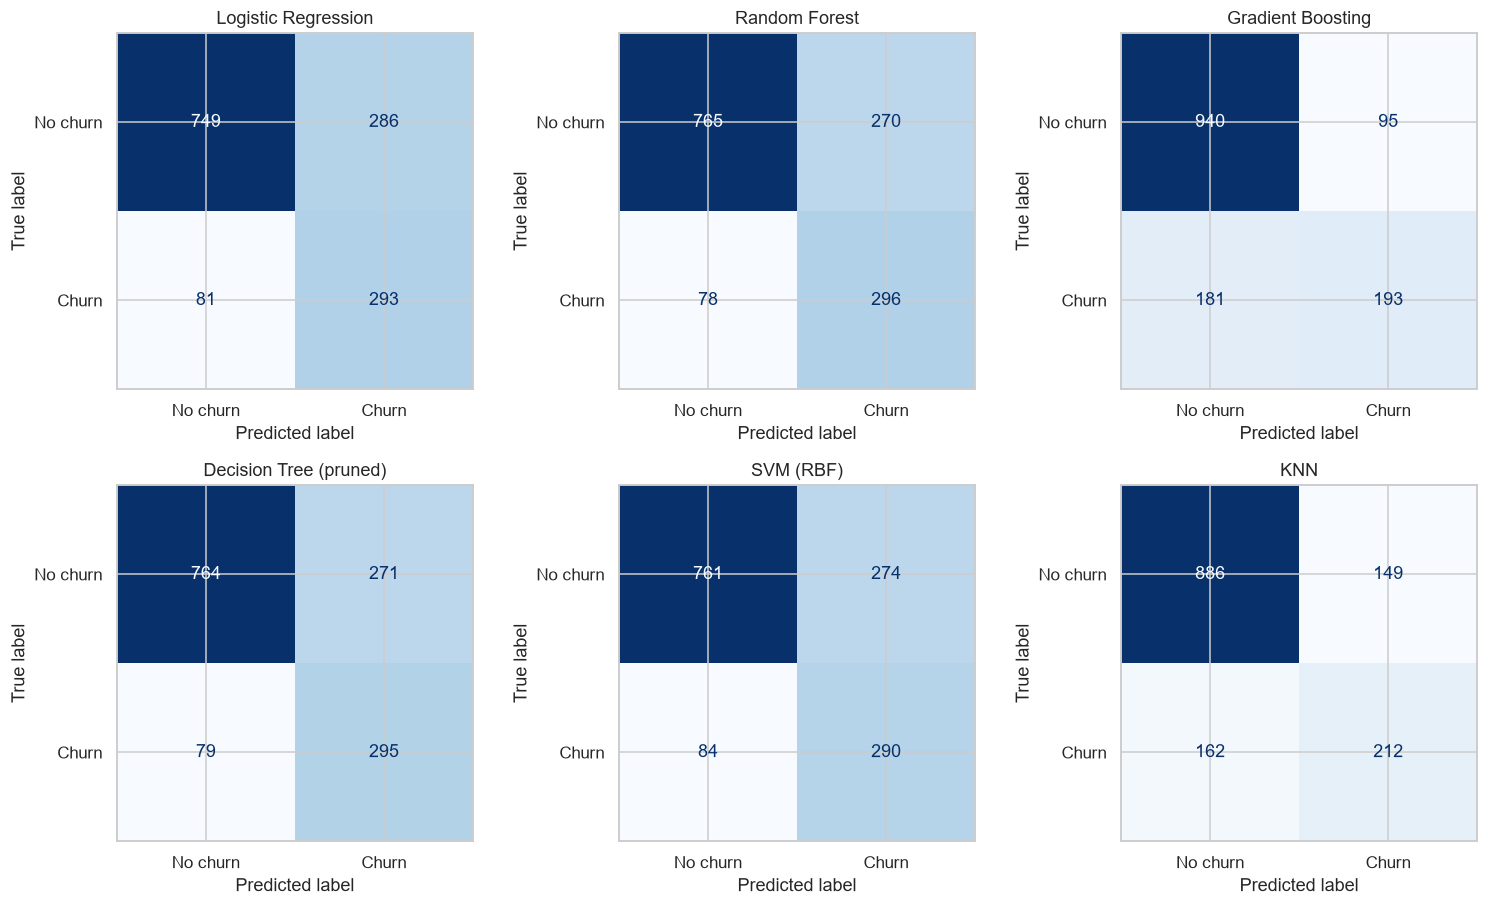

In [20]:
fig, ax = plt.subplots(figsize=(7, 5.5))
for name, m in final_models.items():
    RocCurveDisplay.from_predictions(y_test, scores_of(m, X_test), name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.set_title("ROC curves (test set)"); plt.tight_layout(); plt.show()

n = len(final_models)
cols = 3
fig, axes = plt.subplots(int(np.ceil(n / cols)), cols, figsize=(14, 4.2 * np.ceil(n / cols)))
for ax, (name, m) in zip(axes.ravel(), final_models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test), ax=ax, cmap="Blues",
                                            display_labels=["No churn", "Churn"], colorbar=False)
    ax.set_title(name)
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.tight_layout(); plt.show()

## 11. Model selection and justification
The final model is chosen by a transparent rule: **highest cross-validated ROC-AUC among the tuned models, with a small train–CV gap**, and tie-breaking on recall for churners and simplicity. The test set is used only to *confirm* the choice, not to make it.

In [21]:
cand = tuning.copy()
best_name = cand["Best CV ROC-AUC"].idxmax()
print("Selected model (highest tuned CV ROC-AUC):", best_name)
print(cand.loc[best_name, ["Best CV ROC-AUC", "Train ROC-AUC", "Gap"]].round(4).to_dict())
print("Test set:", test_results.loc[best_name].round(3).to_dict())

best_model = final_models[best_name]
print()
print(classification_report(y_test, best_model.predict(X_test), target_names=["No churn", "Churn"]))

Selected model (highest tuned CV ROC-AUC): Gradient Boosting
{'Best CV ROC-AUC': 0.8506, 'Train ROC-AUC': 0.8769, 'Gap': 0.0262}
Test set: {'Accuracy': 0.804, 'Precision': 0.67, 'Recall': 0.516, 'F1': 0.583, 'ROC-AUC': 0.846, 'PR-AUC': 0.662}

              precision    recall  f1-score   support

    No churn       0.84      0.91      0.87      1035
       Churn       0.67      0.52      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409
weighted avg       0.79      0.80      0.80      1409



### Threshold tuning for the business goal

Missing a churner (false negative) costs more than a wasted retention offer (false positive). The default 0.5 threshold is not necessarily the best; lowering it raises recall at the cost of precision.

In [22]:
proba = best_model.predict_proba(X_test)[:, 1] if hasattr(best_model, "predict_proba") else None
if proba is not None:
    thr_rows = []
    for t in [0.2, 0.3, 0.4, 0.5, 0.6]:
        p = (proba >= t).astype(int)
        thr_rows.append({"Threshold": t, "Precision": precision_score(y_test, p),
                         "Recall": recall_score(y_test, p), "F1": f1_score(y_test, p)})
    display(pd.DataFrame(thr_rows).set_index("Threshold").round(3))

,Precision,Recall,F1
Threshold,,,
0.2,0.480,0.834,0.609
0.3,0.539,0.767,0.634
0.4,0.600,0.642,0.620
0.5,0.670,0.516,0.583
0.6,0.738,0.369,0.492


### What drives churn? (permutation importance on the test set)

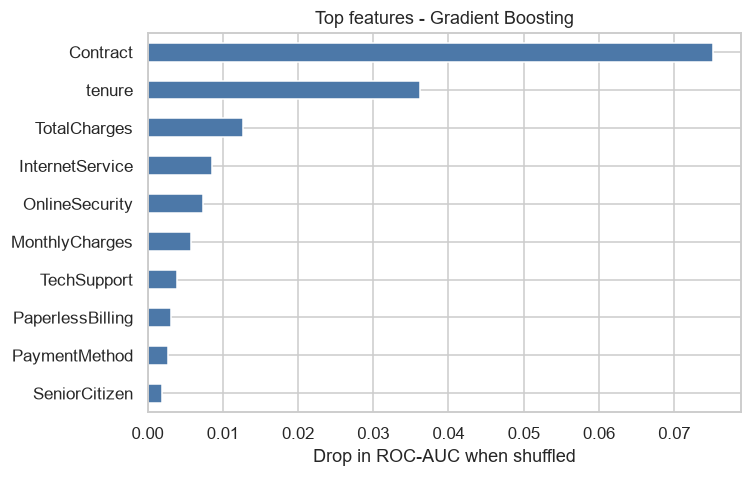

In [23]:
perm = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=True).tail(10)

plt.figure(figsize=(7, 4.5))
imp.plot(kind="barh", color="#4C78A8")
plt.xlabel("Drop in ROC-AUC when shuffled"); plt.title(f"Top features - {best_name}")
plt.tight_layout(); plt.show()

## 12. Conclusion

- **Problem:** binary classification of telecom customer churn on 7,043 customers, ~27% churners (imbalanced), so recall, F1, ROC-AUC and PR-AUC were used alongside accuracy.
- **Validation:** stratified 80/20 split plus stratified 5-fold CV inside leak-free pipelines; the test set was used once, only to confirm the final choice.
- **Overfitting found:** the unrestricted **Decision Tree** memorised the training data (train ROC-AUC 1.00 vs CV 0.66, gap 0.34). Limiting depth and leaf size (`max_depth=6`, `min_samples_leaf=50`) cut the gap to 0.03 and raised CV ROC-AUC to 0.83. The untuned **Random Forest** also overfit (train 1.00 vs CV 0.82); tuning reduced the gap to 0.03.
- **Underfitting / capacity limit:** no tuned model underfits badly. Very shallow trees (depth 1-2) clearly underfit in the validation curve. **Logistic Regression** has almost no train-CV gap (0.004), meaning it is low-variance but limited to linear patterns.
- **Selected model: tuned Gradient Boosting.** It has the highest CV ROC-AUC (0.851) with a small train-CV gap (0.026) and stable folds. On the test set it scores ROC-AUC 0.846, PR-AUC 0.662, accuracy 0.804, precision 0.67, recall 0.52, F1 0.58 at the default 0.5 threshold.
- **Honest caveat:** tuned Gradient Boosting, Random Forest and Logistic Regression are within about 0.5% CV ROC-AUC of each other, so the differences are small. Logistic Regression is the simpler, more interpretable alternative if explainability matters more than the last bit of performance.
- **Business use:** the default threshold misses almost half of the churners. Lowering the threshold to 0.3 raises recall to about 0.77 (precision 0.54, F1 0.63), which suits a retention campaign where a wasted offer costs less than a lost customer.
- **Drivers of churn:** short tenure, month-to-month contracts, fiber-optic internet and electronic-check payment; long contracts and tech support/online security protect against churn.
- **Limitations and next steps:** a single data snapshot with no cost matrix or time component. Future work: SMOTE inside CV, XGBoost/LightGBM, SHAP explanations and cost-sensitive threshold selection.